# Week 4 - Day 2: Probability

## Task 1: Basic Probability Calculations

### Business Scenario
An e-commerce company analyzes customer coupon usage and repeat purchases using a contingency table.

- Event A: Customer used a coupon.
- Event B: Customer made a repeat purchase.

The objective is to calculate basic probability, joint probability, and conditional probability.

In [22]:
import numpy as np
import pandas as pd

In [23]:
# Create contingency table
data = {
    "Repeat Purchase": [30, 10],
    "No Repeat Purchase": [20, 40]
}

contingency_table = pd.DataFrame(
    data,
    index=["Coupon Used", "No Coupon"]
)

contingency_table

,Repeat Purchase,No Repeat Purchase
Coupon Used,30,20
No Coupon,10,40


In [24]:
# Total number of customers
total_customers = 100

# Event A: Customer used a coupon
P_A = 50 / total_customers

# Event B: Customer made a repeat purchase
P_B = 40 / total_customers

# Event A and B: Used coupon and made repeat purchase
P_A_intersection_B = 30 / total_customers

# Repeat purchase given coupon was used
P_B_given_A = 30 / 50

# Coupon used given repeat purchase
P_A_given_B = 30 / 40

# Display probability results
print("P(A) - Coupon Usage:", P_A)
print("P(B) - Repeat Purchase:", P_B)
print("P(A ∩ B) - Coupon & Repeat Purchase:", P_A_intersection_B)
print("P(B | A) - Repeat Purchase given Coupon:", P_B_given_A)
print("P(A | B) - Coupon given Repeat Purchase:", P_A_given_B)

P(A) - Coupon Usage: 0.5
P(B) - Repeat Purchase: 0.4
P(A ∩ B) - Coupon & Repeat Purchase: 0.3
P(B | A) - Repeat Purchase given Coupon: 0.6
P(A | B) - Coupon given Repeat Purchase: 0.75


### Conclusion

Probability analysis helped measure customer purchasing behavior.

- 50% of customers used coupons.
- 40% of customers made repeat purchases.
- 30% of all customers used coupons and made repeat purchases.
- 60% of coupon users made repeat purchases.
- 75% of repeat purchasers had used coupons.

The analysis indicates that coupon users had a higher repeat-purchase rate in this sample. Businesses can use probability analysis to evaluate promotional strategies, customer behavior, and marketing effectiveness.

## Task 2: Normal Distribution

A normal distribution is a probability distribution where data is distributed symmetrically around the mean, forming a bell-shaped curve.

In a normal distribution:
- Mean: The center of the distribution.
- Standard Deviation: Measures how spread out the data is.
- Most values are concentrated around the mean.
- The curve is symmetrical.

In [26]:
import matplotlib.pyplot as plt
from scipy.stats import norm

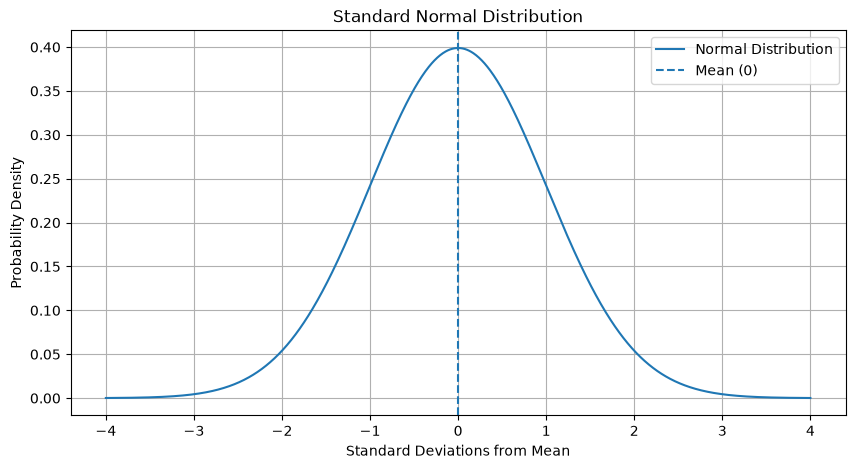

In [27]:
# Parameters of the normal distribution
mean = 0
std_dev = 1

# Generate x values
x = np.linspace(-4, 4, 1000)

# Calculate normal distribution values
y = norm.pdf(x, mean, std_dev)

# Plot the normal distribution
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Normal Distribution")

plt.title("Standard Normal Distribution")
plt.xlabel("Standard Deviations from Mean")
plt.ylabel("Probability Density")
plt.axvline(mean, linestyle="--", label="Mean (0)")

plt.grid(True)
plt.legend()
plt.show()

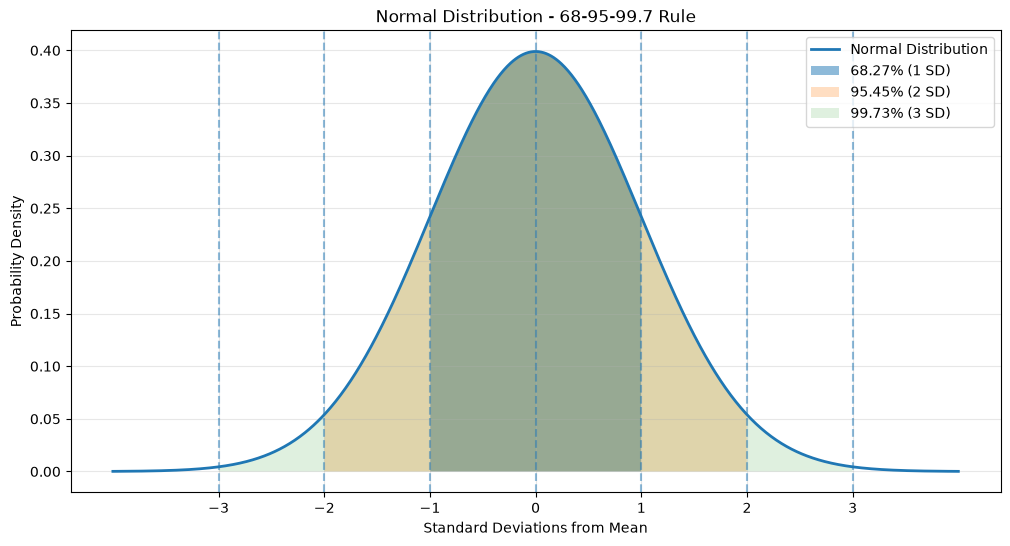

Normal distribution graph saved successfully!


In [28]:
# Plot the normal distribution with standard deviation regions
plt.figure(figsize=(12, 6))

x = np.linspace(-4, 4, 1000)
y = norm.pdf(x, 0, 1)

plt.plot(x, y, linewidth=2, label="Normal Distribution")

# Shade regions
plt.fill_between(x, y, where=(x >= -1) & (x <= 1), alpha=0.5, label="68.27% (1 SD)")
plt.fill_between(x, y, where=(x >= -2) & (x <= 2), alpha=0.25, label="95.45% (2 SD)")
plt.fill_between(x, y, where=(x >= -3) & (x <= 3), alpha=0.15, label="99.73% (3 SD)")

# Mark standard deviations
for value in [-3, -2, -1, 0, 1, 2, 3]:
    plt.axvline(value, linestyle="--", alpha=0.5)

plt.title("Normal Distribution - 68-95-99.7 Rule")
plt.xlabel("Standard Deviations from Mean")
plt.ylabel("Probability Density")
plt.xticks([-3, -2, -1, 0, 1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)

# Save graph
from pathlib import Path

if Path("week4/day2_probability/outputs").exists():
    output_dir = Path("week4/day2_probability/outputs")
elif Path("outputs").exists():
    output_dir = Path("outputs")
else:
    output_dir = Path("week4/day2_probability/outputs")

output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(output_dir / "normal_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Normal distribution graph saved successfully!")

## Task 3: Binomial Distribution Simulation

A binomial distribution models the number of successes in a fixed number of independent trials, where each trial has the same probability of success.

Business Scenario:
An e-commerce company estimates that 20% of customers will purchase a product after clicking an advertisement.

We simulate 1000 advertising clicks to analyze the number of successful purchases.

Parameters:
- Number of trials (n): 100
- Probability of success (p): 0.20
- Number of simulations: 1000

In [29]:
# Binomial distribution simulation

n = 100              # Number of trials
p = 0.20             # Probability of success
simulations = 1000   # Number of simulations

# Simulate binomial outcomes
binomial_data = np.random.binomial(n, p, simulations)

# Display basic statistics
print("Mean number of successes:", np.mean(binomial_data))
print("Expected number of successes:", n * p)
print("Minimum successes:", np.min(binomial_data))
print("Maximum successes:", np.max(binomial_data))

Mean number of successes: 19.9
Expected number of successes: 20.0
Minimum successes: 6
Maximum successes: 34


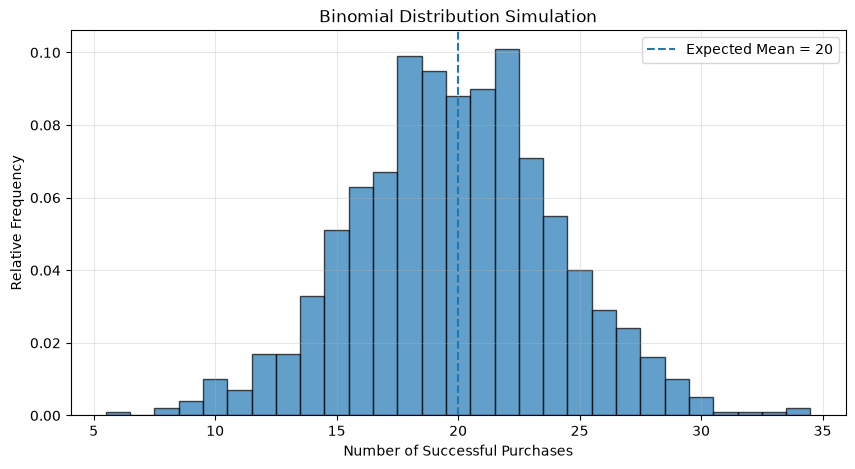

Binomial distribution graph saved successfully!


In [30]:
# Plot the binomial distribution
plt.figure(figsize=(10, 5))

plt.hist(
    binomial_data,
    bins=np.arange(binomial_data.min(), binomial_data.max() + 2) - 0.5,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(n * p, linestyle="--", label="Expected Mean = 20")

plt.title("Binomial Distribution Simulation")
plt.xlabel("Number of Successful Purchases")
plt.ylabel("Relative Frequency")
plt.legend()
plt.grid(alpha=0.3)

# Save the graph
plt.savefig(output_dir / "binomial_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Binomial distribution graph saved successfully!")

### Conclusion

The binomial distribution was simulated using NumPy with 100 trials and a 20% probability of success across 1,000 simulations.

The average simulated number of successes was approximately 19.9, which is close to the theoretical expected value of 20.

This demonstrates how binomial distribution can model business outcomes such as customer conversions, product purchases, and campaign success rates.

In [31]:
# Central Limit Theorem Simulation

# Generate a non-normal population (exponential distribution)
population = np.random.exponential(scale=2, size=100000)

# Sampling parameters
sample_size = 50
num_samples = 1000

# Calculate means of repeated random samples
sample_means = []

for _ in range(num_samples):
    sample = np.random.choice(population, size=sample_size)
    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

# Display statistics
print("Population Mean:", np.mean(population))
print("Mean of Sample Means:", np.mean(sample_means))
print("Sample Size:", sample_size)
print("Number of Samples:", num_samples)

Population Mean: 1.9852523269692588
Mean of Sample Means: 1.982431921671689
Sample Size: 50
Number of Samples: 1000


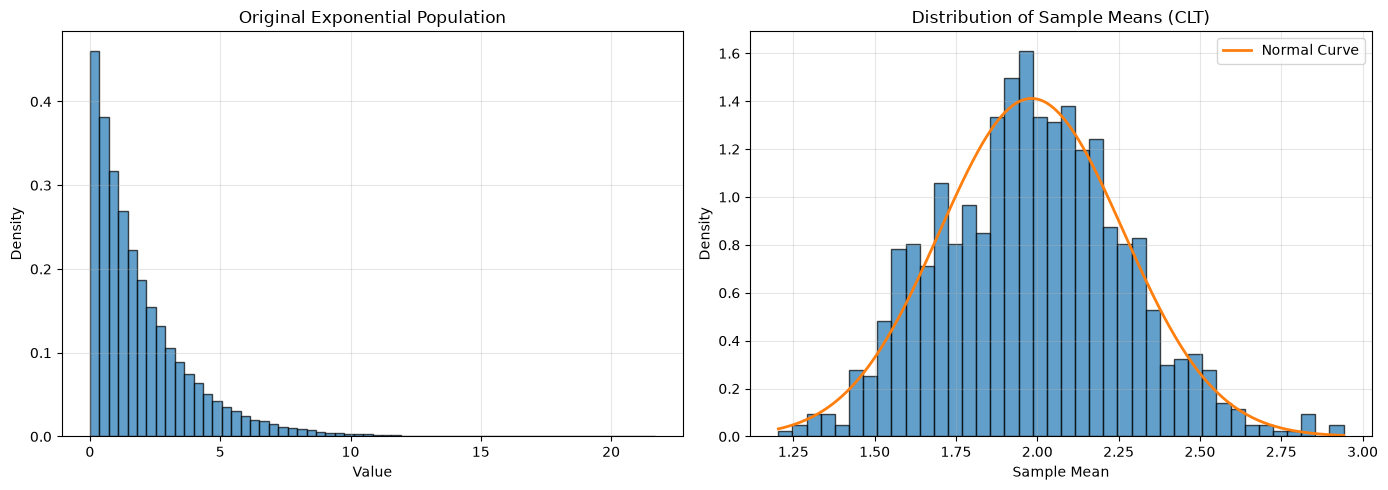

CLT simulation graph saved successfully!


In [32]:
# Visualize the Central Limit Theorem
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original population distribution
axes[0].hist(population, bins=60, density=True, alpha=0.7, edgecolor="black")
axes[0].set_title("Original Exponential Population")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Density")
axes[0].grid(alpha=0.3)

# Distribution of sample means
axes[1].hist(sample_means, bins=40, density=True, alpha=0.7, edgecolor="black")

# Overlay a normal curve
mean_sample = np.mean(sample_means)
std_sample = np.std(sample_means)

x_clt = np.linspace(sample_means.min(), sample_means.max(), 300)
normal_curve = norm.pdf(x_clt, mean_sample, std_sample)

axes[1].plot(x_clt, normal_curve, linewidth=2, label="Normal Curve")
axes[1].set_title("Distribution of Sample Means (CLT)")
axes[1].set_xlabel("Sample Mean")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig(output_dir / "clt_simulation.png", dpi=300, bbox_inches="tight")
plt.show()

print("CLT simulation graph saved successfully!")

### Conclusion

The Central Limit Theorem was demonstrated using an exponential population distribution.

A population of 100,000 observations was generated, and 1,000 random samples of size 50 were selected. The mean of each sample was calculated.

Although the original population was skewed, the distribution of sample means became approximately normal.

The mean of the sample means was close to the original population mean, demonstrating the Central Limit Theorem.

This concept is useful in business analytics, survey analysis, quality control, forecasting, and statistical decision-making.